# Finding “even” and “odd” inside a CNN

This notebook applies the technique from Klerings et al., *Steering Language Models in Multi-Token Generation: A Case Study on Tense and Aspect*, EMNLP 2025, to a CNN.

We want to check whether a human-understandable idea, in this case even and odd numbers, appears as a roughly consistent direction in the embedding space. We also want to check whether the model actually uses that direction when making a prediction.

The basic premise is that the difference between even and odd might look like roughly the same displacement across many examples in the embedding space.

We train a simple CNN on MNIST and look for an axis that separates even numbers from odd numbers. Then we add that direction back into the network and see whether its predictions change. We compare it with a random direction as a control.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

seed = 7
torch.manual_seed(seed)
np.random.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "not available"
print(f"Device: {device} — {gpu_name}")

Device: cuda — NVIDIA GeForce RTX 5070


## Training the network

In [2]:
mnist_mean, mnist_std = 0.1307, 0.3081
image_transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((mnist_mean,), (mnist_std,))]
)

train_dataset = datasets.MNIST(
    root="data", train=True, download=True, transform=image_transform
)
test_dataset = datasets.MNIST(
    root="data", train=False, download=True, transform=image_transform
)

loader_generator = torch.Generator().manual_seed(seed)
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=0,
    pin_memory=device.type == "cuda",
    generator=loader_generator,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=0,
    pin_memory=device.type == "cuda",
)

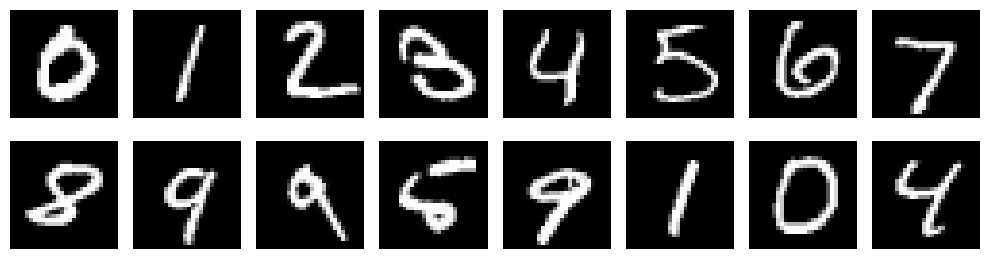

In [3]:
sample_ids = [3, 2, 1, 18, 4, 15, 11, 0, 61, 12, 7, 8, 9, 5, 10, 6]
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, sample_id in zip(axes.flat, sample_ids):
    image, _ = test_dataset[sample_id]
    image = image * mnist_std + mnist_mean
    ax.imshow(image.squeeze(), cmap="gray")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
class SmallMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.embedding = nn.Linear(64 * 7 * 7, 128)
        self.classifier = nn.Linear(128, 10)

    def forward(self, images, return_activations=False):
        hidden1 = F.max_pool2d(F.relu(self.conv1(images)), 2)
        hidden2 = F.max_pool2d(F.relu(self.conv2(hidden1)), 2)
        embedding = F.relu(self.embedding(hidden2.flatten(1)))
        logits = self.classifier(embedding)

        if return_activations:
            activations = {
                "conv1": hidden1.mean(dim=(2, 3)),
                "conv2": hidden2.mean(dim=(2, 3)),
                "embedding": embedding,
            }
            return logits, activations

        return logits


model = SmallMNISTCNN().to(device)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Parameters: {parameter_count:,}")

Parameters: 421,642


The model has two convolutional blocks, a 128-dimensional embedding, and a final linear classifier. Let's investigate the 128-dimensional embedding layer, as well as the two earlier layers.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
training_history = []
start_time = time.perf_counter()

for epoch in range(1, 4):
    model.train()
    loss_sum = 0.0
    seen = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=device.type == "cuda",
        ):
            loss = F.cross_entropy(model(images), labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += loss.item() * len(labels)
        seen += len(labels)

    model.eval()
    correct = 0
    total = 0
    with torch.inference_mode():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            correct += (model(images).argmax(1) == labels).sum().item()
            total += len(labels)

    row = {
        "epoch": epoch,
        "loss": loss_sum / seen,
        "test_accuracy": correct / total,
    }
    training_history.append(row)
    print(
        f"Epoch {epoch}: loss {row['loss']:.4f}, "
        f"test accuracy {row['test_accuracy']:.2%}"
    )

training_seconds = time.perf_counter() - start_time
model.eval()
print(f"Training time: {training_seconds:.1f} seconds")

Epoch 1: loss 0.2357, test accuracy 97.79%
Epoch 2: loss 0.0592, test accuracy 98.58%
Epoch 3: loss 0.0399, test accuracy 98.74%
Training time: 9.3 seconds


## Can one straight line read parity?

We collect the hidden activations for every image. At the convolutional layers, we average the spatial positions so that each channel gives us one number. The last hidden layer is already a 128-dimensional vector.

For each layer, we fit a linear reader on the training activations:

$$d_{read} = (\Sigma + \lambda I)^{-1}(\mu_{even}-\mu_{odd}).$$

This is regularized linear discriminant analysis. It points from the odd mean toward the even mean while accounting for the normal spread of the activations.

In [6]:
@torch.inference_mode()
def collect_activations(loader):
    chunks = {"conv1": [], "conv2": [], "embedding": []}
    label_chunks = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        _, activations = model(images, return_activations=True)
        for layer_name in chunks:
            chunks[layer_name].append(activations[layer_name].float().cpu())
        label_chunks.append(labels)

    joined = {
        layer_name: torch.cat(parts) for layer_name, parts in chunks.items()
    }
    return joined, torch.cat(label_chunks)


train_activations, train_labels = collect_activations(train_loader)
test_activations, test_labels = collect_activations(test_loader)
train_is_even = train_labels.remainder(2).eq(0)
test_is_even = test_labels.remainder(2).eq(0)

In [7]:
def fit_read_direction(features, is_even):
    even_mean = features[is_even].mean(0)
    odd_mean = features[~is_even].mean(0)
    centered = features - features.mean(0)
    covariance = centered.T @ centered / (len(features) - 1)
    ridge = 1e-3 * covariance.diag().mean()
    direction = torch.linalg.solve(
        covariance + ridge * torch.eye(features.shape[1]),
        even_mean - odd_mean,
    )
    direction = direction / direction.norm()
    train_projection = features @ direction
    threshold = 0.5 * (
        train_projection[is_even].mean() + train_projection[~is_even].mean()
    )
    return direction, threshold


layer_names = ["conv1", "conv2", "embedding"]
read_directions = {}
probe_accuracies = {}
write_directions = {}

for layer_name in layer_names:
    read_direction, threshold = fit_read_direction(
        train_activations[layer_name], train_is_even
    )
    read_directions[layer_name] = read_direction
    test_projection = test_activations[layer_name] @ read_direction
    probe_accuracies[layer_name] = (
        ((test_projection > threshold) == test_is_even).float().mean().item()
    )

    mean_difference = (
        train_activations[layer_name][train_is_even].mean(0)
        - train_activations[layer_name][~train_is_even].mean(0)
    )
    write_directions[layer_name] = mean_difference / mean_difference.norm()

shuffle_generator = torch.Generator().manual_seed(seed + 1)
shuffled_control_accuracies = []
for _ in range(20):
    shuffled_even = train_is_even[
        torch.randperm(len(train_is_even), generator=shuffle_generator)
    ]
    shuffled_direction, shuffled_threshold = fit_read_direction(
        train_activations["embedding"], shuffled_even
    )
    shuffled_accuracy = (
        (
            (test_activations["embedding"] @ shuffled_direction > shuffled_threshold)
            == test_is_even
        )
        .float()
        .mean()
        .item()
    )
    shuffled_control_accuracies.append(shuffled_accuracy)

shuffled_control_accuracy = np.mean(shuffled_control_accuracies)

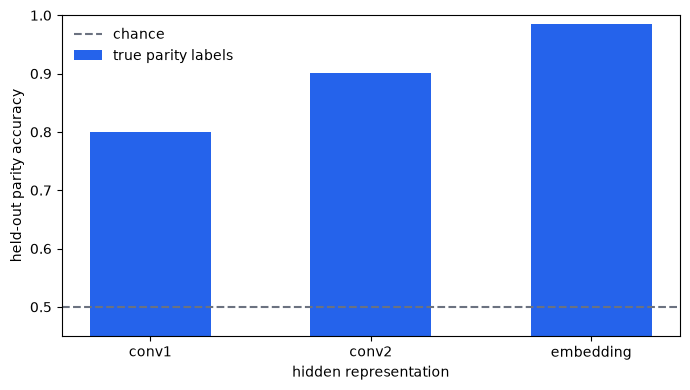

Embedding probe accuracy: 98.57%
Shuffled-label control: 48.95% average (37.56% to 59.78%)


In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
positions = np.arange(len(layer_names))
ax.bar(
    positions,
    [probe_accuracies[layer_name] for layer_name in layer_names],
    width=0.55,
    color="#2563eb",
    label="true parity labels",
)
ax.axhline(0.5, color="#6b7280", linestyle="--", label="chance")
ax.set_xticks(positions, layer_names)
ax.set_xlabel("hidden representation")
ax.set_ylabel("held-out parity accuracy")
ax.set_ylim(0.45, 1.0)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"Embedding probe accuracy: {probe_accuracies['embedding']:.2%}")
print(
    f"Shuffled-label control: {shuffled_control_accuracy:.2%} average "
    f"({min(shuffled_control_accuracies):.2%} to "
    f"{max(shuffled_control_accuracies):.2%})"
)

By the embedding layer, a straight line separates even and odd digits very well. Scrambling the labels drops the result back to around chance. So this means parity can be read from the hidden state but not whether changing that signal will change the number.

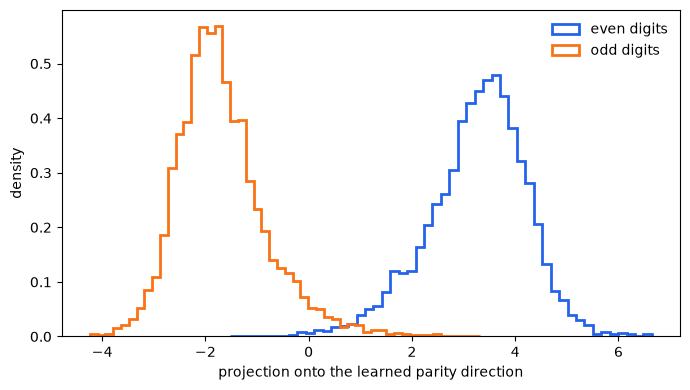

In [10]:
embedding_read_direction = read_directions["embedding"]
embedding_read_projection = (
    test_activations["embedding"] @ embedding_read_direction
).numpy()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(
    embedding_read_projection[test_is_even.numpy()],
    bins=50,
    density=True,
    histtype="step",
    linewidth=2,
    color="#2563eb",
    label="even digits",
)
ax.hist(
    embedding_read_projection[~test_is_even.numpy()],
    bins=50,
    density=True,
    histtype="step",
    linewidth=2,
    color="#f97316",
    label="odd digits",
)
ax.set_xlabel("projection onto the learned parity direction")
ax.set_ylabel("density")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Writing parity back into the network

The best direction for reading is not always the best direction for writing. For steering, we use the simpler difference between the even mean and the odd mean:

$$d_{write} = \frac{\mu_{even}-\mu_{odd}}
{\lVert\mu_{even}-\mu_{odd}\rVert}.$$

For a test embedding `h`, we make this change:

$$h' = h + s\,\Delta\,d_{write}.$$

Positive values of `s` move toward even. Negative values move toward odd. The input image and the model weights do not change.

In [11]:
embedding_write_direction = write_directions["embedding"]
train_write_projection = train_activations["embedding"] @ embedding_write_direction
parity_separation = (
    train_write_projection[train_is_even].mean()
    - train_write_projection[~train_is_even].mean()
).item()

steering_strengths = np.linspace(-2.0, 2.0, 25)
test_embeddings_device = test_activations["embedding"].to(device)
write_direction_device = embedding_write_direction.to(device)
even_digit_ids = torch.tensor([0, 2, 4, 6, 8], device=device)

random_generator = torch.Generator().manual_seed(seed + 2)
random_direction = torch.randn(
    embedding_write_direction.shape, generator=random_generator
)
random_direction -= (
    random_direction @ embedding_write_direction
) * embedding_write_direction
random_direction = (random_direction / random_direction.norm()).to(device)

steered_even_probability = []
random_even_probability = []
even_prediction_rate = []

with torch.inference_mode():
    for strength in steering_strengths:
        amount = float(strength * parity_separation)
        steered_logits = model.classifier(
            test_embeddings_device + amount * write_direction_device
        )
        random_logits = model.classifier(
            test_embeddings_device + amount * random_direction
        )
        steered_probabilities = steered_logits.softmax(1)
        random_probabilities = random_logits.softmax(1)

        steered_even_probability.append(
            steered_probabilities[:, even_digit_ids].sum(1).mean().item()
        )
        random_even_probability.append(
            random_probabilities[:, even_digit_ids].sum(1).mean().item()
        )
        steered_predictions = steered_logits.argmax(1).cpu()
        even_prediction_rate.append(
            steered_predictions.remainder(2).eq(0).float().mean().item()
        )

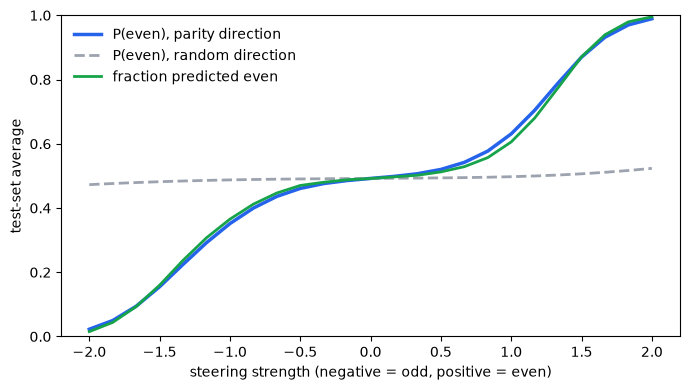

P(even), parity direction: 2.3% to 98.9%
P(even), random direction: 47.3% to 52.3%


In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    steering_strengths,
    steered_even_probability,
    color="#2563eb",
    linewidth=2.5,
    label="P(even), parity direction",
)
ax.plot(
    steering_strengths,
    random_even_probability,
    color="#9ca3af",
    linewidth=2,
    linestyle="--",
    label="P(even), random direction",
)
ax.plot(
    steering_strengths,
    even_prediction_rate,
    color="#16a34a",
    linewidth=2,
    label="fraction predicted even",
)
ax.set_xlabel("steering strength (negative = odd, positive = even)")
ax.set_ylabel("test-set average")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(
    f"P(even), parity direction: "
    f"{steered_even_probability[0]:.1%} to {steered_even_probability[-1]:.1%}"
)
print(
    f"P(even), random direction: "
    f"{random_even_probability[0]:.1%} to {random_even_probability[-1]:.1%}"
)

The parity direction changes the model's output in a smooth way. The random direction barely changes it. So the final classifier does respond to the parity direction. This is evidence that the final classifier responds to the parity direction.

## Finding a 7 that changes to an even prediction

We now search the test set for a real 7 that the original model classifies correctly as 7, but classifies as an even digit after steering.

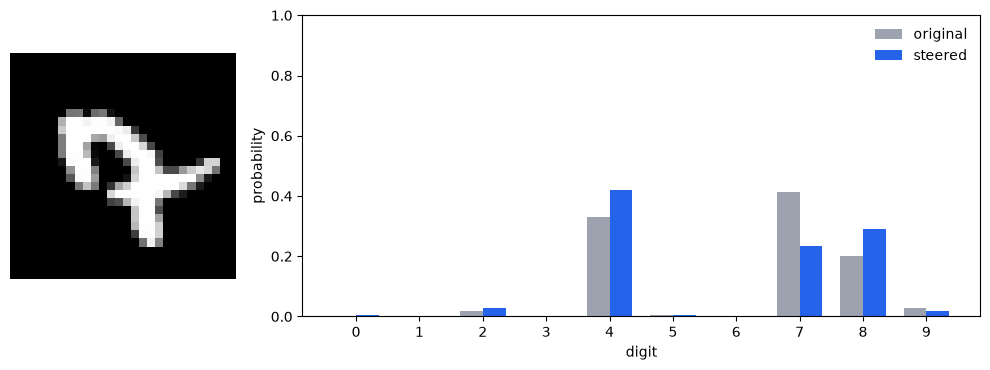

Test index: 3316
True digit: 7
Original prediction: 7 (odd)
Steered prediction: 4 (even)
Steering strength: 0.1


In [12]:
with torch.inference_mode():
    original_logits = model.classifier(test_embeddings_device)
    original_probabilities = original_logits.softmax(1)
    original_predictions = original_logits.argmax(1).cpu()

selected_index = None
selected_strength = None
selected_steered_logits = None

for strength in np.arange(0.1, 4.01, 0.1):
    with torch.inference_mode():
        candidate_logits = model.classifier(
            test_embeddings_device
            + float(strength * parity_separation) * write_direction_device
        )
    candidate_predictions = candidate_logits.argmax(1).cpu()
    candidates = (
        (test_labels == 7)
        & (original_predictions == 7)
        & candidate_predictions.remainder(2).eq(0)
    )
    if candidates.any():
        selected_index = int(torch.where(candidates)[0][0])
        selected_strength = float(strength)
        selected_steered_logits = candidate_logits[selected_index]
        break

if selected_index is None:
    raise RuntimeError("No correctly classified 7 changed to an even prediction.")

original_probability = original_probabilities[selected_index].cpu().numpy()
steered_probability = selected_steered_logits.softmax(0).cpu().numpy()
original_digit = int(original_probability.argmax())
steered_digit = int(steered_probability.argmax())
selected_image, true_digit = test_dataset[selected_index]
display_image = selected_image * mnist_std + mnist_mean

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 3.8),
    gridspec_kw={"width_ratios": [1, 3]},
)
axes[0].imshow(display_image.squeeze(), cmap="gray")
axes[0].axis("off")

digit_positions = np.arange(10)
width = 0.36
axes[1].bar(
    digit_positions - width / 2,
    original_probability,
    width,
    color="#9ca3af",
    label="original",
)
axes[1].bar(
    digit_positions + width / 2,
    steered_probability,
    width,
    color="#2563eb",
    label="steered",
)
axes[1].set_xticks(digit_positions)
axes[1].set_xlabel("digit")
axes[1].set_ylabel("probability")
axes[1].set_ylim(0, 1)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"Test index: {selected_index}")
print(f"True digit: {true_digit}")
print(f"Original prediction: {original_digit} (odd)")
print(f"Steered prediction: {steered_digit} (even)")
print(f"Steering strength: {selected_strength:.1f}")

The image is still a 7. We did not change the pixels or the model weights. We only moved its hidden embedding toward the even side, and the model changed its answer to an even digit.

## What we learned

The CNN was only trained to recognize digits, but even and odd became easy to separate in its hidden state.

The steering test goes one step further. Moving an embedding along the parity direction changes the model's prediction in the expected direction. A random direction does not have the same effect.

This does not prove that the CNN understands parity as an abstract mathematical rule. It shows that the model has a useful even-versus-odd direction for the MNIST digits it learned.